# Reviewing daily case reports with robust scores and regression

This notebook looks for unusual daily COVID-19 case reports in Uganda and nearby countries. A rolling median/MAD score provides a transparent time-series baseline. A second approach forecasts the 7-day mean from earlier values with Linear Regression, Ridge, Lasso, and SGD regression, then flags unusually large forecast residuals.

The regression comparison applies topics listed in the shared timetable: linear regression, gradient-based fitting, regularization, cross-validation, and performance metrics. We preserve time order: models are selected with expanding time-series cross-validation on the earlier part of each country's series and evaluated on a later holdout. Since the data have no verified reporting-error labels, both methods produce dates for review, not confirmed errors.

## Load and inspect the data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_PATH = Path("data/owid/cases_deaths.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Download the OWID cases and deaths CSV and save it to data/owid/cases_deaths.csv; see the README.")

# Read the header first so the 189 MB source is loaded with only the needed columns.
headers = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()
place_col = "country" if "country" in headers else ("location" if "location" in headers else None)
date_col = "date"
candidate_cols = ["cases_new_per_million", "new_cases_per_million", "cases_new", "new_cases"]
value_col = next((c for c in candidate_cols if c in headers), None)
if place_col is None or date_col not in headers or value_col is None:
    raise ValueError(f"Could not identify required columns. Available columns: {headers}")
raw = pd.read_csv(DATA_PATH, usecols=[place_col, date_col, value_col], low_memory=False)
print("Loaded only these columns:", [place_col, date_col, value_col])
print("Rows and columns:", raw.shape)
display(raw.head())

Loaded only these columns: ['country', 'date', 'new_cases_per_million']
Rows and columns: (617520, 3)


,country,date,new_cases_per_million
0,Afghanistan,2020-01-04,0.0
1,Afghanistan,2020-01-05,0.0
2,Afghanistan,2020-01-06,0.0
3,Afghanistan,2020-01-07,0.0
4,Afghanistan,2020-01-08,0.0


## Choose the measure and countries

Check the dataset's metadata for the indicator definition, units, and original data source before interpreting the results. The code uses new cases per million where available and records which field it selected.

In [2]:
date_col = "date"
place_col = "country" if "country" in raw.columns else ("location" if "location" in raw.columns else None)
if place_col is None or date_col not in raw.columns:
    raise ValueError("Could not find a country/location and date column. Review the OWID file schema.")
candidate_cols = ["cases_new_per_million", "new_cases_per_million", "cases_new", "new_cases"]
value_col = next((c for c in candidate_cols if c in raw.columns), None)
if value_col is None:
    raise ValueError(f"No recognized new-cases column. Available: {raw.columns.tolist()}")

countries = ["Uganda", "Kenya", "Tanzania", "Rwanda"]
df = raw.loc[raw[place_col].isin(countries), [place_col, date_col, value_col]].copy()
df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
df[value_col] = pd.to_numeric(df[value_col], errors="coerce")
df = df.dropna(subset=[date_col]).sort_values([place_col, date_col])
df = df.rename(columns={place_col: "country", date_col: "date", value_col: "reported_cases"})
print("Selected measure:", value_col)
display(df.groupby("country")["reported_cases"].agg(["count", "min", "median", "max"]))
display(df.isna().mean().rename("missing_fraction").to_frame())

Selected measure: new_cases_per_million


,count,min,median,max
country,,,,
Kenya,2479,0.0,0.0,69.102860
Rwanda,2480,0.0,0.0,203.134929
Tanzania,2480,0.0,0.0,312.307695
Uganda,2479,0.0,0.0,437.345409


,missing_fraction
country,0.000000
date,0.000000
reported_cases,0.000202


## Calculate rolling scores and regression forecasts

The rolling median/MAD baseline compares each 7-day mean with recent history. The regression methods minimize squared prediction error: ordinary least squares fits coefficients to reduce \(\sum_i (y_i-\hat y_i)^2\); Ridge adds an \(L_2\) penalty \(\lambda\sum_jeta_j^2\), while Lasso adds an \(L_1\) penalty \(\lambda\sum_j|eta_j|\). Both penalties shrink coefficients; Lasso may shrink some to zero. SGD updates coefficients using a gradient step \(	heta_{t+1}=	heta_t-\eta
abla_	heta\ell_i(	heta_t)\), which can be faster on larger data but depends on the learning settings. We also fit Linear Regression, Ridge, Lasso, and SGD regression to predict the week-to-week change from lagged values. The forecast is that predicted change added to a weekly-naive forecast, which makes the comparison direct and avoids extrapolating a global time trend across changing epidemic phases. Ridge and Lasso shrink coefficients to control model complexity; SGD fits the linear objective through iterative gradient-based updates.

For each country, the first 80% of usable days is the training period. Expanding time-series cross-validation compares models on weekly change using mean absolute error and selects regularization strength. The final model is compared with a simple forecast that repeats the value from one week earlier. Regression residuals are flagged when they exceed a robust threshold derived only from training residuals. This keeps the later test period out of model selection and cutoff setting.

In [3]:
window = 28
threshold = 3.5
scored_parts = []
regression_rows = []

for country, group in df.groupby("country", sort=False):
    group = group.sort_values("date").copy()
    group["cases_7day"] = group["reported_cases"].rolling(7, min_periods=4).mean()

    # Rolling robust baseline: only earlier observations define each day's reference.
    previous = group["cases_7day"].shift(1)
    baseline = previous.rolling(window, min_periods=14).median()
    deviation = (previous - baseline).abs().rolling(window, min_periods=14).median()
    scale = (1.4826 * deviation).replace(0, np.nan)
    group["robust_z"] = (group["cases_7day"] - baseline) / scale
    group["flag_for_review"] = group["robust_z"].abs() >= threshold

    # Regression features use lagged values, so the forecast does not see the day being predicted.
    group["lag_1"] = group["cases_7day"].shift(1)
    group["lag_7"] = group["cases_7day"].shift(7)
    group["lag_14"] = group["cases_7day"].shift(14)
    group["prior_28day_mean"] = group["cases_7day"].shift(1).rolling(28, min_periods=14).mean()
    feature_cols = ["lag_1", "lag_7", "lag_14", "prior_28day_mean"]
    model_data = group.dropna(subset=["cases_7day"] + feature_cols).copy()
    # Predict the week-to-week change, then add it to the weekly-naive forecast.
    model_data["change_vs_week"] = model_data["cases_7day"] - model_data["lag_7"]

    split_at = int(len(model_data) * 0.80)
    train = model_data.iloc[:split_at]
    test = model_data.iloc[split_at:]
    X_train, y_train = train[feature_cols], train["change_vs_week"]
    X_test, y_test = test[feature_cols], test["cases_7day"]
    cv = TimeSeriesSplit(n_splits=5)

    candidates = {
        "Linear Regression": Pipeline([("scale", StandardScaler()), ("regressor", LinearRegression())]),
        "Ridge": Pipeline([("scale", StandardScaler()), ("regressor", Ridge())]),
        "Lasso": Pipeline([("scale", StandardScaler()), ("regressor", Lasso(max_iter=10000))]),
        "SGD Regression": Pipeline([("scale", StandardScaler()), ("regressor", SGDRegressor(
            loss="squared_error", penalty="l2", max_iter=5000, tol=1e-4, random_state=42
        ))]),
    }
    grids = {
        "Ridge": {"regressor__alpha": [0.1, 1.0, 10.0, 100.0]},
        "Lasso": {"regressor__alpha": [0.001, 0.01, 0.1, 1.0]},
        "SGD Regression": {"regressor__alpha": [0.0001, 0.001, 0.01]},
    }

    fitted = {}
    cv_errors = {}
    for name, estimator in candidates.items():
        if name == "Linear Regression":
            cv_mae = -cross_val_score(
                estimator, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error", n_jobs=1
            ).mean()
            estimator.fit(X_train, y_train)
            fitted[name] = estimator
            cv_errors[name] = cv_mae
        else:
            search = GridSearchCV(
                estimator, grids[name], cv=cv, scoring="neg_mean_absolute_error", n_jobs=1
            )
            search.fit(X_train, y_train)
            fitted[name] = search.best_estimator_
            cv_errors[name] = -search.best_score_

    best_name = min(cv_errors, key=cv_errors.get)
    best_model = fitted[best_name]
    predicted_change = best_model.predict(X_test)
    naive_predictions = X_test["lag_7"].to_numpy()
    predictions = naive_predictions + predicted_change

    # Use training residuals to define the residual reference; never set the cutoff from the test period.
    train_level_predictions = X_train["lag_7"].to_numpy() + best_model.predict(X_train)
    train_residuals = train["cases_7day"].to_numpy() - train_level_predictions
    residual_center = float(np.median(train_residuals))
    residual_mad = float(np.median(np.abs(train_residuals - residual_center)))
    if not np.isfinite(residual_mad) or residual_mad == 0:
        residual_mad = float(np.std(train_residuals)) or 1.0
    test_residuals = y_test.to_numpy() - predictions
    residual_z = (test_residuals - residual_center) / (1.4826 * residual_mad)

    group["regression_prediction"] = np.nan
    group["regression_residual_z"] = np.nan
    group["regression_flag"] = False
    group.loc[test.index, "regression_prediction"] = predictions
    group.loc[test.index, "regression_residual_z"] = residual_z
    group.loc[test.index, "regression_flag"] = np.abs(residual_z) >= threshold

    regression_rows.append({
        "country": country,
        "selected_model": best_name,
        "CV MAE for weekly change": cv_errors[best_name],
        "test MAE": mean_absolute_error(y_test, predictions),
        "test RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "test R2": r2_score(y_test, predictions),
        "weekly-naive MAE": mean_absolute_error(y_test, naive_predictions),
        "test days": len(test),
        "regression flags": int((np.abs(residual_z) >= threshold).sum()),
    })
    scored_parts.append(group)

scored = pd.concat(scored_parts, ignore_index=True)
regression_metrics = pd.DataFrame(regression_rows)
print("Rolling MAD flags by country:")
display(scored.groupby("country")["flag_for_review"].agg(["sum", "count"]))
print("Time-ordered regression results. Compare the model with the weekly-naive forecast:")
display(regression_metrics)
print("Rolling MAD review dates:")
display(scored.loc[scored.flag_for_review, ["country", "date", "reported_cases", "cases_7day", "robust_z"]].head(20))
print("Regression residual review dates in the held-out period:")
display(scored.loc[scored.regression_flag, ["country", "date", "reported_cases", "cases_7day", "regression_prediction", "regression_residual_z"]].head(20))

Rolling MAD flags by country:


,sum,count
country,,
Kenya,119,2480
Rwanda,78,2480
Tanzania,118,2480
Uganda,155,2480


Time-ordered regression results. Compare the model with the weekly-naive forecast:


,country,selected_model,CV MAE for weekly change,test MAE,test RMSE,test R2,weekly-naive MAE,test days,regression flags
0,Kenya,Linear Regression,0.169490,0.029609,0.029620,-198.589761,0.000897,493,0
1,Rwanda,Lasso,0.380365,0.050032,0.050051,-168.780435,0.000892,493,0
2,Tanzania,Lasso,0.167541,0.052628,0.052775,-32.243106,0.004841,493,18
3,Uganda,Lasso,0.389402,0.098231,0.098245,-360.020041,0.002266,493,0


Rolling MAD review dates:


,country,date,reported_cases,cases_7day,robust_z
84,Kenya,2020-03-28,0.055297,0.063197,31.701066
85,Kenya,2020-03-29,0.129026,0.081629,20.234723
86,Kenya,2020-03-30,0.073729,0.071096,8.431134
87,Kenya,2020-03-31,0.147459,0.089529,6.969738
88,Kenya,2020-04-01,0.165891,0.089529,5.877705
89,Kenya,2020-04-02,0.405512,0.147459,6.879806
90,Kenya,2020-04-03,0.755726,0.247520,9.892531
91,Kenya,2020-04-04,0.000000,0.239620,8.768380
92,Kenya,2020-04-05,0.073729,0.231721,7.804822
93,Kenya,2020-04-06,0.294918,0.263319,6.425412


Regression residual review dates in the held-out period:


,country,date,reported_cases,cases_7day,regression_prediction,regression_residual_z
6947,Tanzania,2025-06-13,0.000000,0.028699,0.072026,4.375176
6948,Tanzania,2025-06-14,0.000000,0.028699,0.071932,4.417630
6949,Tanzania,2025-06-15,0.000000,0.028699,0.071837,4.460083
6950,Tanzania,2025-06-16,0.000000,0.000000,0.078296,-11.335115
6964,Tanzania,2025-06-30,0.293609,0.041944,0.057034,17.061327
6971,Tanzania,2025-07-07,0.092719,0.013246,0.085934,-8.815807
6978,Tanzania,2025-07-14,0.139078,0.019868,0.063602,4.192801
6985,Tanzania,2025-07-21,0.000000,0.000000,0.069853,-7.542146
6992,Tanzania,2025-07-28,0.123625,0.017661,0.055368,6.900254
6999,Tanzania,2025-08-04,0.000000,0.000000,0.067692,-6.571416


## Plot and interpret the review flags

The figure marks rolling MAD flags and regression-residual flags separately. A date can be flagged by one method and not the other because the MAD method measures departure from recent history, while regression measures departure from a fitted forecast.

MAE measures average absolute error, RMSE penalizes larger misses more, and R-squared compares the model with predicting the test mean. In this run, the selected linear or regularized regression did not beat the weekly-naive forecast on the later holdout for any of the four countries, and test R-squared was negative. The regression residual flags therefore should not be presented as validated alerts. This is an important model-comparison finding: the changing reporting pattern and distribution shift made the fitted regression less useful than the simple baseline. The rolling MAD output remains a screening aid only, because the series have no verified error labels.

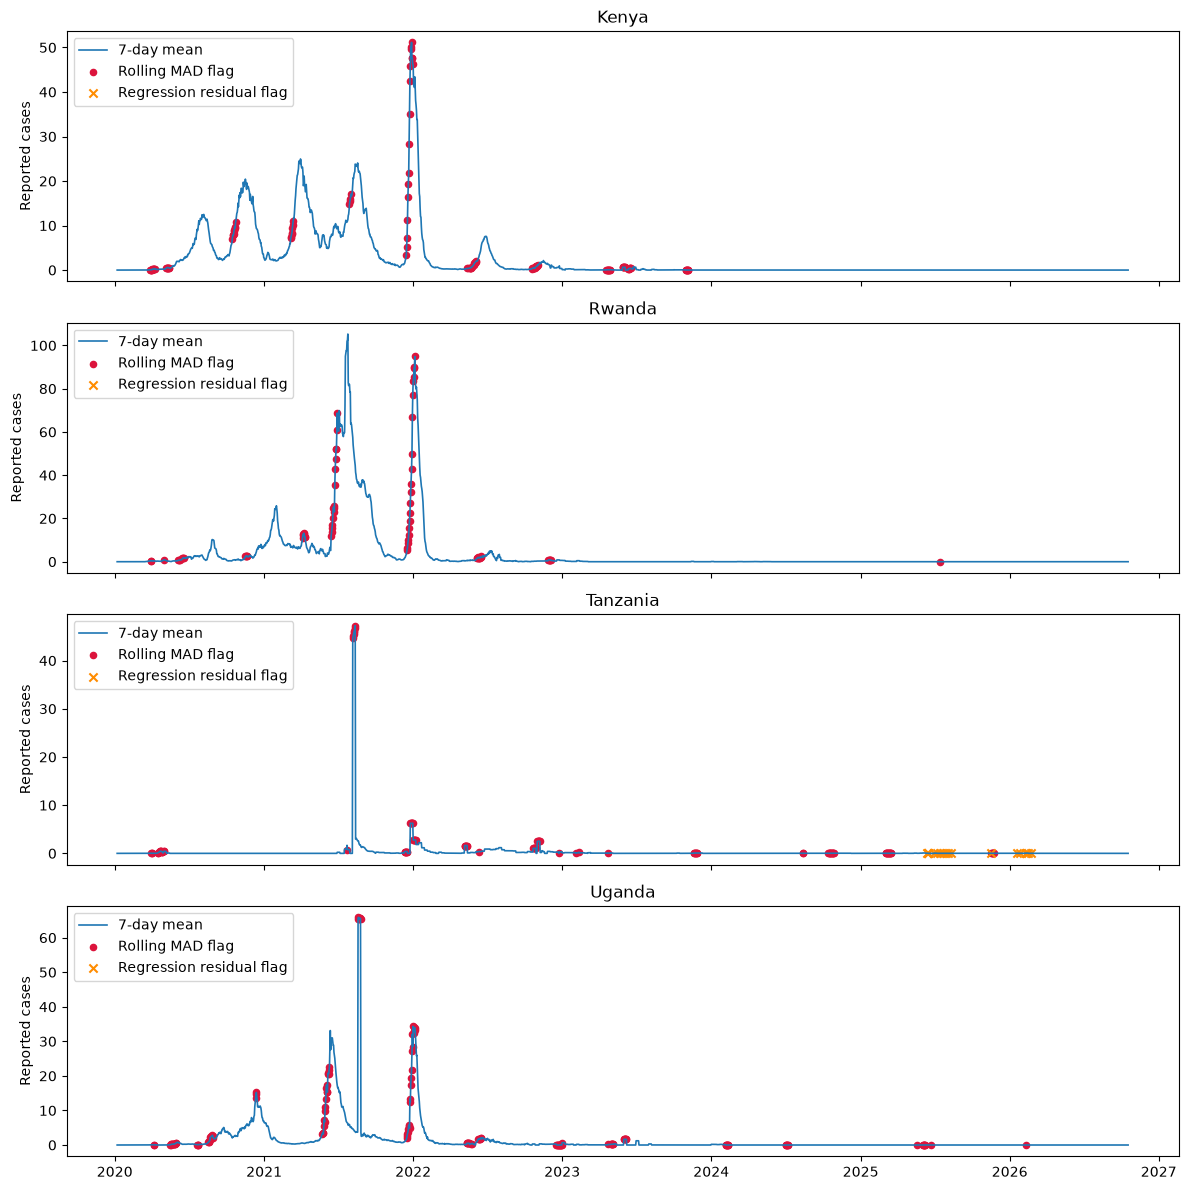

In [4]:
countries_in_data = scored["country"].unique()
fig, axes = plt.subplots(len(countries_in_data), 1, figsize=(12, 3 * len(countries_in_data)), sharex=True)
for ax, country in zip(np.atleast_1d(axes), countries_in_data):
    group = scored[scored.country == country]
    ax.plot(group.date, group.cases_7day, linewidth=1.2, label="7-day mean")
    mad_flags = group[group.flag_for_review]
    ax.scatter(mad_flags.date, mad_flags.cases_7day, color="crimson", s=20,
               label="Rolling MAD flag")
    regression_flags = group[group.regression_flag]
    ax.scatter(regression_flags.date, regression_flags.cases_7day, color="darkorange",
               marker="x", s=35, label="Regression residual flag")
    ax.set_title(country)
    ax.set_ylabel("Reported cases")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

A flagged date is a prompt to inspect the source and surrounding reports. A spike may reflect a backlog submitted at once; a drop may reflect a delayed or incomplete report. The regression model is selected by time-series cross-validation and judged against a weekly-naive forecast, but the data do not contain verified error labels. Do not interpret a lower forecast error or a flag count as proof that the method detects true reporting mistakes. Discuss the train/test split, regularization, and metric choice in your report, and note that results can change when the public data file is updated.